# Analysis

In [1]:
import pandas as pd
import seaborn as sns

df = pd.read_csv('../data/processed/dataset.csv')

sns.set_theme(palette='Greens_d')

## How does electricity demand change with temperature and season?

<Axes: xlabel='max_temperature', ylabel='demand'>

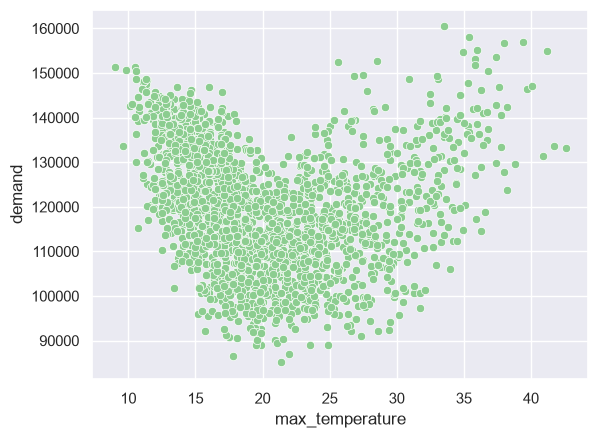

In [2]:

sns.scatterplot(data=df, x='max_temperature', y='demand')

<Axes: xlabel='min_temperature', ylabel='demand'>

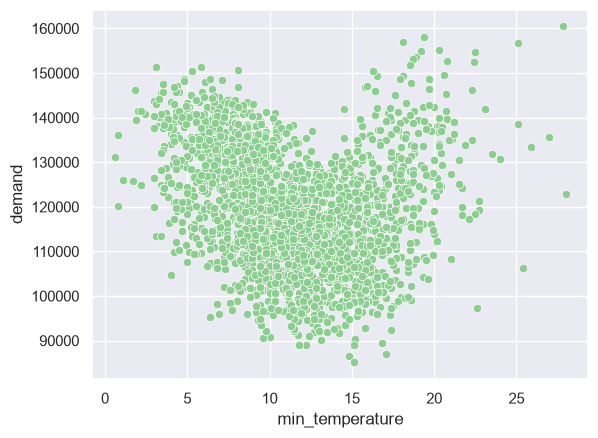

In [3]:
sns.scatterplot(data=df, x='min_temperature', y='demand')

With the help of the graphs above, we can see that demand is relatively lower during 10-15 min temperatures and 20-25 max temperatures. During lower min and max temperatures there seems to be on average more demand. But, during higher min and max temperatures occur the highest demands.

In [4]:
seasonal_demand = df.groupby('season')['demand'].agg(
    ['min', 'max', 'mean', 'median', 'std']
)

print(seasonal_demand)

              min         max           mean       median           std
season                                                                 
Autumn  92097.070  152599.125  116262.249262  116321.6000  10929.638199
Spring  86891.230  154632.335  114554.787204  114543.0675  10801.992444
Summer  85094.375  160437.565  116262.186969  114179.4250  14656.156745
Winter  98917.175  151355.430  130658.189927  132583.6400   9800.342953


<Axes: xlabel='season', ylabel='demand'>

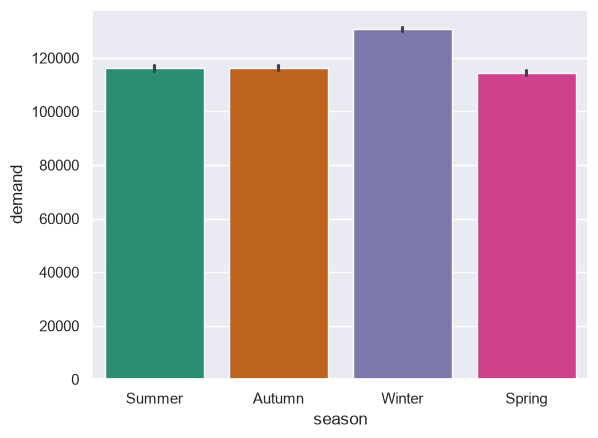

In [5]:
sns.barplot(data=df, x='season', y='demand', hue='season', legend=False, estimator='mean', palette='Dark2')

On average, winter (months June, July and August) has the highest demand.

Text(0.5, 0.98, 'Temperature and Demand, Between Different Seasons')

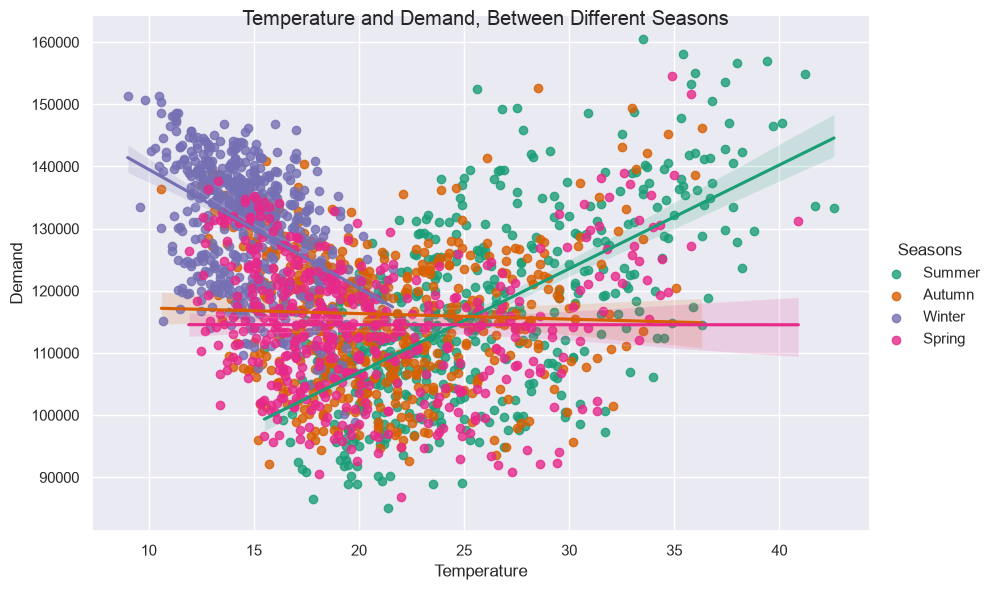

In [6]:
g = sns.lmplot(
    data=df,
    x='max_temperature',
    y='demand',
    hue='season',
    height=6,
    aspect=1.5,
    palette='Dark2'
)

g.set_axis_labels('Temperature', 'Demand')
g.legend.set_title('Seasons')
g.fig.suptitle('Temperature and Demand, Between Different Seasons')

## Are high-demand days associated with higher prices?

Text(0.5, 0.98, 'Demand and RRP')

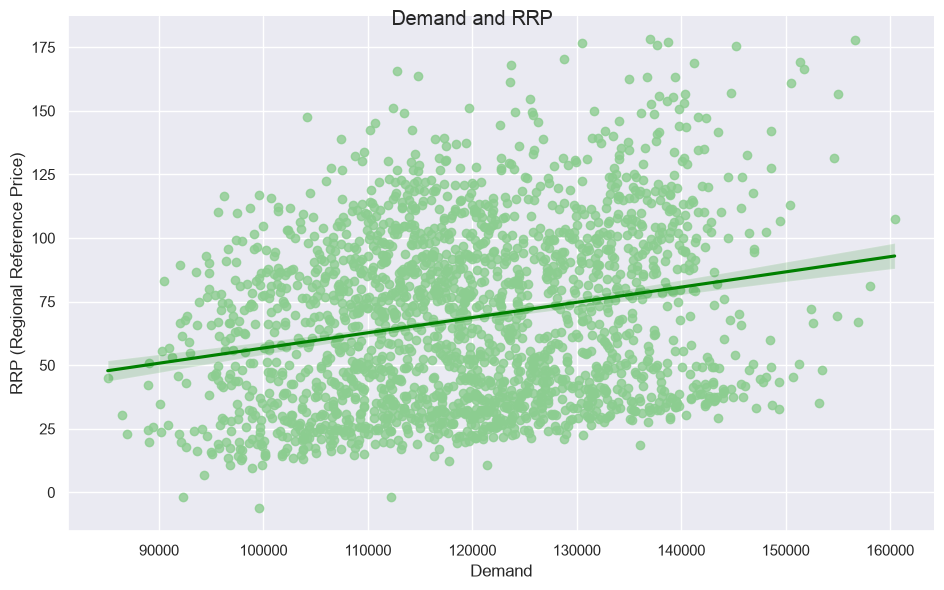

In [14]:
l = sns.lmplot(data=df, x='demand', y='rrp', height=6, aspect=1.6, line_kws={"color": "green"})

l.set_axis_labels('Demand', 'RRP (Regional Reference Price)')
l.fig.suptitle('Demand and RRP')

In [8]:
demand_rrp = df[['demand', 'rrp']]

demand_rrp.corr()

,demand,rrp
demand,1.000000,0.232464
rrp,0.232464,1.000000
